# DS 3000 - Assignment 4

**Student Name**: Muyuan Ma

**Date**: Feb 5, 2023


### Submission Instructions
Submit this `ipynb` file to canvas.

The `ipynb` format stores outputs from the last time you ran the notebook.  (When you open a notebook it has the figures and outputs of the last time you ran it too).  To ensure that your submitted `ipynb` file represents your latest code, make sure to give a fresh run `Kernel > Restart & Run All` just before uploading the `ipynb` file to Canvas.

### Academic Integrity

**Writing your homework is an individual effort.**  You may discuss general python problems with other students but under no circumstances should you observe another student's code which was written for this assignment, from this year or past years.  Pop into office hours or DM us in MS Teams if you have a specific question about your work or if you would like another pair of eyes or talk through your code.

Don't forget to cite websites which helped you solve a problem in a unique way.  You can do this in markdown near the code or with a simple one-line comment. You do not need to cite the official python documentation.

**Documentation / style counts for credit**  Please refer to the Pep-8 style, to improve the readability and consistency of your Python code. For more information, read the following article [How to Write Beautiful Python Code With PEP 8](https://realpython.com/python-pep8/) or ask your TA's for tips.

**NOTE:<span style='color:red'> Write python expressions to answer ALL questions below and ensure that you use the `print()` function to display the output.</span>** Each question should be answered in a new code cell. For example, your solution for question 1.1 should be in a different code cell from your solution for question 1.2.

## Data Science Problem (50 pts)
### Instructions

You are hired as a Data Scientist for the NYC Taxi and Limousine Commission (TLC) and this company routinely collects trip data from all licensed cabs in NY. Your team would like to use this data in the future to understand how New Yorkers use these taxis. Your first assignment is to **analyze the data of the Green Taxis, and determine if its a viable source.**

Your supervisor has requested that you perform your analysis using data from February 2020 and would like for you to present your findings during the next team meeting. Use a Jupyter notebook to explain your data wrangling and analytical steps to your colleagues. 

**Data & Documentation**

- **Data Source:** https://d37ci6vzurychx.cloudfront.net/trip-data/green_tripdata_2020-02.parquet
- **Data Dictionary:** [Green Trips Data Dictionary](https://www1.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_green.pdf).

The TLC trip record data and a description of the initiative can be found at the following link: https://www1.nyc.gov/site/tlc/about/tlc-trip-record-data.page

**`Note:`** Ensure that you explain the results from each question.


**In this assignment you will use the Pandas library. Pandas allows us to load data that's stored in a various formats, e.g. excel, csv, txt, parquet, etc. In this assignment, you will learn to read data in parquet format which is one of the preferred formats when working with `Big Data`. [Click here to learn more about parquet files](https://towardsdatascience.com/csv-files-for-storage-no-thanks-theres-a-better-option-72c78a414d1d)**

I also provided starter code below to help you to read the data in parquet format. First, you'll need to install a new library called *fastparquet*.

In [1]:
#run this cell to install the fast parquet library
!pip install fastparquet

In [2]:
import pandas as pd

## 1. Load the data
Load the NYC Green Taxi Trip Records data directly from the URL into a data frame called tripdata_df. 

In [3]:
#let's load the data into a dataframe

tripdata_df = pd.read_parquet(path = 'https://d37ci6vzurychx.cloudfront.net/trip-data/green_tripdata_2020-02.parquet', #provide the URL to the data source
                      engine = 'fastparquet')

#Note: you'll notice two new things. 1) We are using a new function called `read_parquet()` which indicates that we are 
#      reading data in parquet format. 2) We used the fastparquet library as the engine. 
#      That's it! Pandas will load the data into a dataframe. You can now use the dataframe for EDA.

# Reminder: How does Pandas read other file formats?
# 1. Excel files: pd.read_excel()
# 2. CSV Files: pd.read_csv()
# ... and now you know how to read parquet files using pd.read_parquet()


## 2. Inspect the Data (3 pts) 
Inspect the data to: 1) identify its dimensions, and 2) indicate if the variables have suitable types.

In [4]:
# identify the dimension of the data
print('dimension:' + str(tripdata_df.shape))

dimension:(398632, 20)


In [5]:
# look for the data type of each variable
print(tripdata_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398632 entries, 0 to 398631
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   VendorID               398632 non-null  int64         
 1   lpep_pickup_datetime   398632 non-null  datetime64[ns]
 2   lpep_dropoff_datetime  398632 non-null  datetime64[ns]
 3   store_and_fwd_flag     317739 non-null  object        
 4   RatecodeID             317739 non-null  float64       
 5   PULocationID           398632 non-null  int64         
 6   DOLocationID           398632 non-null  int64         
 7   passenger_count        317739 non-null  float64       
 8   trip_distance          398632 non-null  float64       
 9   fare_amount            398632 non-null  float64       
 10  extra                  398632 non-null  float64       
 11  mta_tax                398632 non-null  float64       
 12  tip_amount             398632 non-null  floa

1)The dimension is 398632 X 20.

2)Some variables do not have suitable types. The "passanger_count", "RatecodeID", "payment_type", and "trip_type" variables are discrete data and should all be int64 instead of float64."store_and_fwd_flag" variable should be string instead of object

## 3. Missing Values (5 pts) 
Evaluate the frequency of missing values in the dataset. Are missing values an isolated case or a widespread issue? What method would you recommend to handle missing data?

In [6]:
# check the number of missing data for each column.
print(tripdata_df.isnull().sum())

VendorID                      0
lpep_pickup_datetime          0
lpep_dropoff_datetime         0
store_and_fwd_flag        80893
RatecodeID                80893
PULocationID                  0
DOLocationID                  0
passenger_count           80893
trip_distance                 0
fare_amount                   0
extra                         0
mta_tax                       0
tip_amount                    0
tolls_amount                  0
ehail_fee                398632
improvement_surcharge         0
total_amount                  0
payment_type              80893
trip_type                 80894
congestion_surcharge      80893
dtype: int64


In [7]:
# check the number of missing data for each row.
print(tripdata_df.isnull().sum(axis=1).sort_values(ascending = False))

398631    7
344706    7
344699    7
344700    7
344701    7
         ..
132875    1
132874    1
132873    1
132872    1
199316    1
Length: 398632, dtype: int64


Those missing values are a widespread issue. I recommand to first delete ehail_fee column since every value is null here, and delete improvement_surcharge as well since there's no such data type in the dictionary. Then delte those rows that
has 4 or more missing variables, and finally use imputation that import median or mode value into the missing data.

## 4. Types of Data (5 pts) 
Are there any categorical data in this dataset. If they exist, identify at least two variables and indicate if  they are nominal or ordinal (hint: read the data dictionary above which describes all field in the data)

Yes, there are categorical data in this dataset.
"payment_type" is an categorical data. It is nominal because there's no order for each payment type.
"VendorID" is an categorical data. It is nominal because there's no order for LPEP provider company.

## 5. Invalid Data (5 pts) 
Explore the data to determine if there are any invalid values. Demonstrate at least three issues that you found.

In [8]:
# check every RatecodeID representing different locations of the end of the trip.
print(tripdata_df['RatecodeID'].value_counts(dropna=True))

1.0     309477
5.0       7246
2.0        620
4.0        263
3.0        130
99.0         2
6.0          1
Name: RatecodeID, dtype: int64


In [9]:
# check every VendorID representing different LPEP providers
print(tripdata_df['VendorID'].value_counts(dropna=True))

2    345899
1     52704
6        29
Name: VendorID, dtype: int64


In [10]:
# check whether there is any negative total amount in descending order. 
print(tripdata_df[tripdata_df.total_amount < 0]['total_amount'].value_counts(dropna=True))

-3.80     192
-4.30     174
-3.30     173
-4.80     128
-5.30     111
         ... 
-6.24       1
-85.30      1
-11.80      1
-14.30      1
-39.50      1
Name: total_amount, Length: 93, dtype: int64


There are invalid values.
First, there's two values of 99 existing in RatecodeID variables. RatecodeID variables are expected to be integers between 1 and 6. 99 does not make any sense. 
Second, there's 29 values of 6 existing in VendorID variables. VendorID variables are expected to be only 1 or 2(representing two companies). 6 does not make any sense.
Third, there're negative values in total_amount variable. Total_amount variable should have no negative value.

## 6. Data Preparation (15 pts) 
Based on the issues that you identified in questions 2, 3 & 5 above, perform the appropriate steps to clean the data and prepare the data for analysis. 


In [11]:
# delete ehail_fee column since there's no such variable in the data dictionary
# Then check the dimension to make sure it has been deleted.
tripdata_df.pop('ehail_fee')
print(tripdata_df.shape)

(398632, 19)


In [12]:
# delete congestion_surcharge since there's no such variable in the data dictionary
# Then check the dimension to make sure it has been deleted.
tripdata_df.pop('congestion_surcharge')
print(tripdata_df.shape)

(398632, 18)


In [13]:
# delete rows that has 4 or more missing data variable
tripdata_df = tripdata_df[tripdata_df.isnull().sum(axis=1) < 4]

In [14]:
# check what is the mode result of store_and_fwd_flag vairable
print(tripdata_df['store_and_fwd_flag'].value_counts(dropna=True))

N    316829
Y       910
Name: store_and_fwd_flag, dtype: int64


In [15]:
# give every missing data in store_and_fwd_flag vairable value of 'N'
# then set store_and_fwd_flag data type to str
tripdata_df.loc[tripdata_df['store_and_fwd_flag'].isna(), 'store_and_fwd_flag'] = 'N'
tripdata_df['store_and_fwd_flag'] = tripdata_df['store_and_fwd_flag'].astype('string')

In [16]:
# give every missing data in passenger_count variable a the median value 
# of the number of passanger
# Then set passenger_count data type to be interger
tripdata_df.loc[tripdata_df['passenger_count'].isna(), 'passenger_count'] = tripdata_df['passenger_count'].median()
tripdata_df['passenger_count']  = tripdata_df['passenger_count'].astype(int)

In [17]:
# check what is the mode value of RatecodeID column
print(tripdata_df['RatecodeID'].value_counts(dropna=True))

1.0     309477
5.0       7246
2.0        620
4.0        263
3.0        130
99.0         2
6.0          1
Name: RatecodeID, dtype: int64


In [18]:
# give every missing data in RatecodeID variable a mode value of the RatecodeID
# Then set RatecodeID data type to be interger
tripdata_df.loc[tripdata_df['RatecodeID'].isna(), 'RatecodeID'] = 1.0
tripdata_df['RatecodeID']  = tripdata_df['RatecodeID'].astype(int)

In [19]:
# check what is the mode value in payment_type column
print(tripdata_df['payment_type'].value_counts(dropna=True))

1.0    176530
2.0    138849
3.0      1767
4.0       579
5.0        14
Name: payment_type, dtype: int64


In [20]:
# give every missing data in payment_type variable a mode value of the payment_type
# Then set payment_type data type to be interger
tripdata_df.loc[tripdata_df['payment_type'].isna(), 'payment_type'] = 1.0
tripdata_df['payment_type'] = tripdata_df['payment_type'].astype(int)

In [21]:
# check what is the mode value in trip_type column
print(tripdata_df['trip_type'].value_counts(dropna=True))

1.0    310466
2.0      7272
Name: trip_type, dtype: int64


In [22]:
# give every missing data in trip_type variable a mode value of the trip_type
# Then set trip_data data type to be interger
tripdata_df.loc[tripdata_df['trip_type'].isna(), 'trip_type'] = 1.0
tripdata_df['trip_type'] = tripdata_df['trip_type'].astype(int)

In [23]:
# change all data that has negative value in total amount variable to the mean value.
tripdata_df.loc[tripdata_df['total_amount'] < 0, 'total_amount'] = tripdata_df['total_amount'].mean()

In [24]:
# change all data that equals to 99 in RatecodeID variable to 1(mode value)
tripdata_df.loc[tripdata_df['RatecodeID'] == 99, 'RatecodeID'] = 1

In [25]:
# change all data that equals to 6 in VendorID variable to 2(mode value)
tripdata_df.loc[tripdata_df['VendorID'] == 6, 'VendorID'] = 2

In [26]:
# delete all duplicate values
tripdata_df.drop_duplicates(inplace=True)

In [27]:
# check data type
print(tripdata_df.info())

<class 'pandas.core.frame.DataFrame'>
Int64Index: 317739 entries, 0 to 317738
Data columns (total 18 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   VendorID               317739 non-null  int64         
 1   lpep_pickup_datetime   317739 non-null  datetime64[ns]
 2   lpep_dropoff_datetime  317739 non-null  datetime64[ns]
 3   store_and_fwd_flag     317739 non-null  string        
 4   RatecodeID             317739 non-null  int32         
 5   PULocationID           317739 non-null  int64         
 6   DOLocationID           317739 non-null  int64         
 7   passenger_count        317739 non-null  int32         
 8   trip_distance          317739 non-null  float64       
 9   fare_amount            317739 non-null  float64       
 10  extra                  317739 non-null  float64       
 11  mta_tax                317739 non-null  float64       
 12  tip_amount             317739 non-null  floa

In [28]:
# check whether every value is not-null
print(tripdata_df.isnull().sum())

VendorID                 0
lpep_pickup_datetime     0
lpep_dropoff_datetime    0
store_and_fwd_flag       0
RatecodeID               0
PULocationID             0
DOLocationID             0
passenger_count          0
trip_distance            0
fare_amount              0
extra                    0
mta_tax                  0
tip_amount               0
tolls_amount             0
improvement_surcharge    0
total_amount             0
payment_type             0
trip_type                0
dtype: int64


In [29]:
# check the dimension
print(tripdata_df.shape)

(317739, 18)


In [30]:
# check whether RatecodeID has any invalid value
print(tripdata_df['RatecodeID'].value_counts(dropna=True))

1    309479
5      7246
2       620
4       263
3       130
6         1
Name: RatecodeID, dtype: int64


1, 2, 3, 4, 5, and 6 are all acceptable values. So there's no invalid values here.

In [31]:
# check whether VendorID has any invalid value
print(tripdata_df['VendorID'].value_counts(dropna=True))

2    265035
1     52704
Name: VendorID, dtype: int64


1 and 2 are all acceptable values. So there's no invalid values here.

In [32]:
# check whether total_amount has any invalid value
print(tripdata_df[tripdata_df.total_amount < 0]['total_amount'].value_counts(dropna=True))

Series([], Name: total_amount, dtype: int64)


There's no values exists by selecting the negative values in total_amount column. 
So every values are acceptable.

## 7. Data Analysis (10 pts)
Answer the following question using the prepared data. What is the most expensive and least expensive trip in this dataset and how far did they travel? Explain the results.

In [33]:
# print the datasets with total_amount and trip_distance variables that has the biggest total_amount
print(tripdata_df.sort_values('total_amount').tail(1).loc[:, ['total_amount','trip_distance']])

       total_amount  trip_distance
71544         651.5            1.1


In [34]:
# print the datasets with total_amount and trip_distance variables that has the smallest total_amount
print(tripdata_df.sort_values('total_amount').head(1).loc[:, ['total_amount','trip_distance']])

        total_amount  trip_distance
114937           0.0            0.0


The most expensive trip is number 71544, costing 651.5 US dollars, traveling 1.1 miles. 
This datum does not make too much sense. It's not common to spend 600s US dollars in just about 1 miles by cab.
The least expensive trip is number 114937, costing 0.0 US dollar, traveling 0.0 mile.
This datum does make sense. It's common to sometimes cancel the trip before starting, riding 0 miles and cost 0 dollar. 

## 8. Data Visualization (5 pts) 
Create bar charts that show: 1) the most common way that New Yorkers request/hail a cab and 2) the most common drop-off location (display the top 5 locations). Explain the charts.

AxesSubplot(0.125,0.11;0.775x0.77)


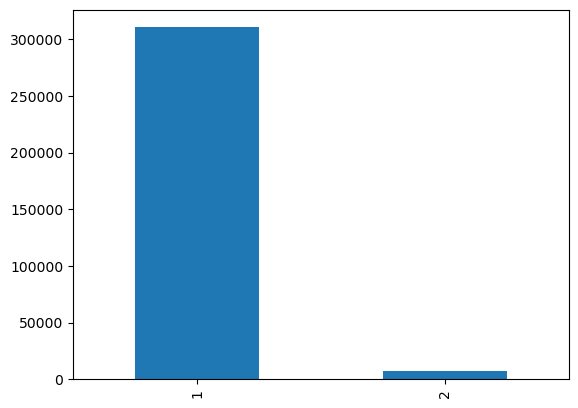

In [35]:
# find out the number of each value exists, then shows out the top 5 values that exists the most times. Finally
# make a bar chart.
top_5_common_way = tripdata_df['trip_type'].value_counts().head()
print(top_5_common_way.plot(kind='bar'))

The top most common way that New Yorkers request a cab is by street-hailing.
The second most common way is by dispatching.
From the chart, we can see bar 1 is much more high than bar 2. This represents that New Yorkers like to request a cab by street-hailing much more than by dispatching. 

AxesSubplot(0.125,0.11;0.775x0.77)


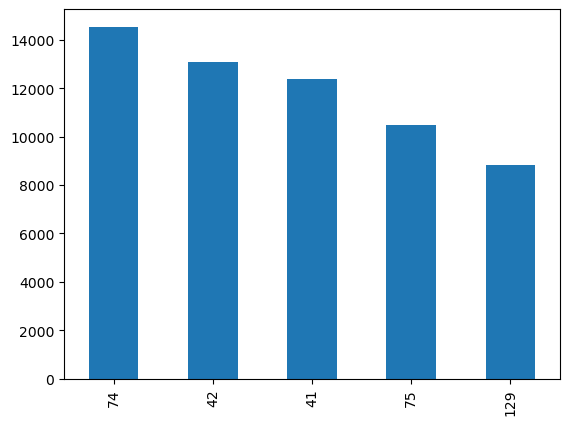

In [36]:
# find out the number of each value exists, then shows out the top 5 values that exists the most times. Finally
# make a bar chart.
top_5_drop_off_location = tripdata_df['DOLocationID'].value_counts().head()
print(top_5_drop_off_location.plot(kind='bar'))

The top most common drop-off location is number 75.
The second most common drop-off location is number 42.
The third most common drop-off location is number 41.
The fourth most common drop-off location is number 75.
The fifth most common drop-off location is number 129.
From the chart, bars are decreasing in a steady rate, meaning there's not a super common drop-off location. The second most common drop-off location is just slightly less popular than the top most common drop-off location.

## 9. Findings (2 pts)
Based on the preliminary analysis, is this data a viable source that can be used by your team in the future to understand how New Yorkers use these taxis? Justify your response.

Based on the prelimimary analysis, I think this data is not a viable source that can be used to understand New Yorker's behavior of using these cabs. Althogh The bar charts showing the way of New Yorkers request a cab and the top 5 most common destination let this dataset seems to be reasonable, it still cannot account for most expensive trip one which generate 600 dollar by riding 1 miles without adding up the tip(described in data dictionary). Besides, there's lots of empty and invalid data exists in this dataset that has been removed before, making this whole dataset less credible. It has to be some errors exist when collecting the data. 